# 12 — Ekstraksi Fitur sMRI DCAN: Morfometri per Parcel

Notebook ini mengubah data sMRI DCAN (ABIDE I + II, 1.638 subjek) menjadi fitur morfometri, **pada parcel yang sama persis dengan time series fMRI** (HCP/Glasser 360 dan Gordon 333 parcel korteks).

| Kelompok fitur | Isi | Dasar |
| :--- | :--- | :--- |
| **A. Morfometri per parcel** | 5 fitur per parcel: **luas permukaan, volume GM, ketebalan, kelengkungan, kedalaman sulkus**. Ditambah volume subkortikal dan 68 wilayah Desikan dari segmentasi | setara 5 fitur morfologi CAS-GNN |

### Data per subjek

| Berkas DCAN | Isi |
| :--- | :--- |
| `thickness`, `curv`, `sulc` (.dscalar, fsLR32k) | ketebalan, kelengkungan, kedalaman sulkus di 32.492 titik per belahan otak |
| `midthickness.surf.gii` (ruang asli subjek) | mesh permukaan untuk menghitung **luas per titik** (sepertiga luas segitiga di sekitarnya) |
| `dseg` (FreeSurfer aparc+aseg, 1 mm) | segmentasi: volume subkortikal dan 68 wilayah Desikan |
| time series fMRI (.ptseries) | daftar titik setiap parcel (untuk memetakan titik → parcel) |

### Catatan perubahan (14 Okt 2026)

Versi sebelumnya notebook ini juga menghitung **jaringan kemiripan struktural (MIND)** dan **kopling struktur–fungsi**. Keduanya hanya dipakai skenario S4 lama (graf struktur–fungsi), yang hasilnya tidak lebih baik dari S3 dan sudah diarsipkan (`_arsip/notebooks_tidak_terpakai/19_skenario4_struktur_fungsi_gatv2.ipynb`). S4 sekarang adalah S3 + optimasi hyperparameter (notebook 19), yang memakai fitur sMRI yang sama dengan S2–S3. Karena itu perhitungan MIND dan kopling dihapus dari notebook ini. Morfometri tidak berubah: nilainya identik dengan versi sebelumnya.

Berkas per subjek lama di `per_subjek/` masih menyimpan kunci MIND, tetapi tidak dibaca lagi.

### Lama proses

±15–30 menit (CPU). Hasil per subjek disimpan, jadi bisa dihentikan dan dilanjutkan. Keluaran ada di `data/processed/fitur_smri_dcan/`.

> **Penjelasan langkah demi langkah** (pada satu subjek contoh, beserta verifikasi bahwa hasilnya identik dengan berkas fitur ini) ada di **notebook 13**. Notebook ini adalah pembuat berkas `fitur_smri_dcan.npz` untuk seluruh 1.638 subjek; jangan dijalankan ulang tanpa perlu.

## 1. Persiapan

In [1]:
import sys
import glob
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists():
    ROOT = ROOT.parent

# ----- Parameter notebook -----
ATLAS = {"hcp2016": "berkas_hcp2016", "gordon2014": "berkas_gordon2014"}
FITUR_TITIK = ["ketebalan", "kelengkungan", "sulkus", "luas", "volume"]     # 5 fitur per titik permukaan
BATAS_SUBJEK = None       # None = seluruh kohort (hanya diubah untuk uji coba)

PROC = ROOT / "data" / "processed"
OUT_DIR = PROC / "fitur_smri_dcan"
PER_DIR = OUT_DIR / "per_subjek"
FIG_DIR = ROOT / "result" / "figure"
TABEL_DIR = ROOT / "result" / "tabel"
for d in (PER_DIR, FIG_DIR, TABEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

kohort = pd.read_csv(PROC / "kohort_dcan.csv")
kohort["idx_asal"] = np.arange(len(kohort))
if BATAS_SUBJEK is not None:
    kohort = kohort.groupby("dataset", group_keys=False).sample(BATAS_SUBJEK // 2, random_state=42).sort_index().reset_index(drop=True)
akhiran = "" if BATAS_SUBJEK is None else f"_uji{BATAS_SUBJEK}"
print(f"Subjek: {len(kohort)} (ABIDE I {int((kohort.dataset == 'abide1').sum())}, ABIDE II {int((kohort.dataset == 'abide2').sum())})")

Subjek: 1638 (ABIDE I 886, ABIDE II 752)


## 2. Pemetaan Titik Permukaan → Parcel

Daftar titik setiap parcel dibaca dari header time series fMRI (CIFTI *parcels axis*). Parcel korteks didefinisikan pada mesh template fsLR32k, sehingga **sama untuk semua subjek**. Ini dicek pada beberapa subjek dari dataset dan situs yang berbeda.

In [2]:
STRUKTUR = {"CIFTI_STRUCTURE_CORTEX_LEFT": "L", "CIFTI_STRUCTURE_CORTEX_RIGHT": "R"}

def peta_parcel(berkas):
    ax = nib.load(ROOT / berkas).header.get_axis(1)
    parcel = [(nama, {STRUKTUR[s]: np.asarray(v) for s, v in verts.items() if s in STRUKTUR})
              for nama, verts in zip(ax.name, ax.vertices) if any(s in STRUKTUR for s in verts)]
    return [p[0] for p in parcel], [p[1] for p in parcel]

PARCEL = {}
for a, kol in ATLAS.items():
    nama, titik = peta_parcel(kohort[kol].iloc[0])
    for j in np.linspace(0, len(kohort) - 1, 5).astype(int)[1:]:
        n2, t2 = peta_parcel(kohort[kol].iloc[j])
        assert n2 == nama and all(all(np.array_equal(x[h], y[h]) for h in x) for x, y in zip(titik, t2)), f"parcel {a} berbeda antar subjek"
    PARCEL[a] = (nama, titik)
display(pd.DataFrame({"Atlas": list(PARCEL), "Parcel korteks": [len(v[0]) for v in PARCEL.values()],
                      "Titik per parcel (median)": [int(np.median([sum(len(x) for x in t.values()) for t in v[1]])) for v in PARCEL.values()]}))
print("Definisi parcel identik pada subjek yang dicek (ABIDE I dan II).")

,Atlas,Parcel korteks,Titik per parcel (median)
0,hcp2016,360,132
1,gordon2014,333,84


Definisi parcel identik pada subjek yang dicek (ABIDE I dan II).


## 3. Fitur per Subjek

Untuk setiap subjek:
1. ketebalan, kelengkungan, dan kedalaman sulkus dipetakan ke 32.492 titik per belahan (titik dinding medial bernilai kosong);
2. **luas per titik** dihitung dari mesh ruang asli subjek, dan **volume per titik** = ketebalan × luas;
3. **morfometri per parcel**: luas dan volume dijumlah; ketebalan, kelengkungan, dan sulkus dirata-rata (ketebalan dibobot luas);
4. **volume dari segmentasi**: jumlah voxel (1 mm³) setiap label aparc+aseg.

In [3]:
def luas_titik(berkas_gii):
    g = nib.load(berkas_gii)
    v, t = g.agg_data("NIFTI_INTENT_POINTSET").astype(np.float64), g.agg_data("NIFTI_INTENT_TRIANGLE")
    a = 0.5 * np.linalg.norm(np.cross(v[t[:, 1]] - v[t[:, 0]], v[t[:, 2]] - v[t[:, 0]]), axis=1)
    luas = np.zeros(len(v))
    np.add.at(luas, t.ravel(), np.repeat(a / 3.0, 3))
    return luas

def ke_32k(img):
    """dscalar → dict belahan: array 32.492 titik (NaN untuk titik yang tidak ada, mis. dinding medial)."""
    x, ax = img.get_fdata()[0], img.header.get_axis(1)
    hasil = {}
    for s, h in STRUKTUR.items():
        m = ax.name == s
        arr = np.full(ax.nvertices[s], np.nan)
        arr[ax.vertex[m]] = x[m]
        hasil[h] = arr
    return hasil

def ekstrak(r):
    berkas = PER_DIR / f"{r['dataset']}_{r['sub']}.npz"
    if berkas.exists():
        return
    d = ROOT / "data" / "raw_dcan" / r["dataset"] / r["sub"]
    cari = lambda pola: next(iter(glob.glob(str(d / pola))))
    ket = ke_32k(nib.load(cari("*_space-fsLR32k_thickness.dscalar.nii")))
    kel = ke_32k(nib.load(cari("*_space-fsLR32k_curv.dscalar.nii")))
    sul = ke_32k(nib.load(cari("*_space-fsLR32k_sulc.dscalar.nii")))
    luas = {h: luas_titik(cari(f"*_hemi-{h}_space-T1w_mesh-fsLR32k_midthickness.surf.gii")) for h in "LR"}
    titik = {h: np.column_stack([ket[h], kel[h], sul[h], luas[h], ket[h] * luas[h]]) for h in "LR"}   # 5 fitur
    hasil = {}
    for a, (nama, peta) in PARCEL.items():
        morfo = []
        for p in peta:
            X = np.vstack([titik[h][idx] for h, idx in p.items()])
            X = X[np.isfinite(X).all(1)]
            w = X[:, 3] / X[:, 3].sum()
            morfo.append([X[:, 3].sum(), X[:, 4].sum(), (w * X[:, 0]).sum(), X[:, 1].mean(), X[:, 2].mean()])
        hasil[f"morfo_{a}"] = np.asarray(morfo, dtype=np.float32)
    seg = np.asarray(nib.load(cari("*_space-ACPC_dseg.nii.gz")).dataobj).astype(np.int32)
    lab, n = np.unique(seg[seg > 0], return_counts=True)
    hasil["seg_label"], hasil["seg_mm3"] = lab.astype(np.int32), n.astype(np.float32)
    hasil["luas_total"] = np.float32(sum(luas[h].sum() for h in "LR"))
    np.savez(berkas, **hasil)

t0 = time.perf_counter()
for r in tqdm(kohort.to_dict("records"), desc="ekstraksi sMRI"):
    ekstrak(r)
print(f"Selesai ({(time.perf_counter() - t0) / 60:.1f} menit; ±0 berarti semua dari cache).")

ekstraksi sMRI:   0%|          | 0/1638 [00:00<?, ?it/s]

Selesai (0.0 menit; ±0 berarti semua dari cache).


## 4. Menggabungkan Fitur Seluruh Subjek

Fitur per subjek digabung menjadi satu berkas `fitur_smri_dcan.npz` dengan urutan subjek sama dengan `kohort_dcan.csv`:
- `morfo_<atlas>`: morfometri per parcel korteks (subjek × parcel × 5);
- `seg_mm3`, `seg_label`, `volume_otak_mm3`: volume dari segmentasi;
- `parcel_<atlas>`: nama parcel, dicek sama urutannya dengan parcel korteks *time series* fMRI.

In [4]:
def muat_semua(kunci):
    return np.stack([np.load(PER_DIR / f"{r['dataset']}_{r['sub']}.npz")[kunci] for r in kohort.to_dict("records")])

FITUR = {}
for a, (nama, _) in PARCEL.items():
    R = len(nama)
    FITUR[f"morfo_{a}"] = muat_semua(f"morfo_{a}")                                    # (N, R, 5)
    nama_fc = list(nib.load(ROOT / kohort[ATLAS[a]].iloc[0]).header.get_axis(1).name)
    assert nama_fc[:R] == list(nama), f"urutan parcel korteks FC {a} tidak sama dengan parcel morfometri"
    print(f"{a}: {R} parcel korteks (urutan sama dengan {len(nama_fc)} parcel FC)")

lab_semua = sorted({int(l) for r in kohort.to_dict("records") for l in np.load(PER_DIR / f"{r['dataset']}_{r['sub']}.npz")["seg_label"]})
seg = np.zeros((len(kohort), len(lab_semua)), dtype=np.float32)
for i, r in enumerate(kohort.to_dict("records")):
    z = np.load(PER_DIR / f"{r['dataset']}_{r['sub']}.npz")
    seg[i, np.searchsorted(lab_semua, z["seg_label"])] = z["seg_mm3"]
FITUR["seg_mm3"] = seg
FITUR["volume_otak_mm3"] = seg.sum(1)

np.savez(OUT_DIR / f"fitur_smri_dcan{akhiran}.npz", **FITUR, seg_label=np.array(lab_semua), sub=kohort["sub"].to_numpy(),
         dataset=kohort["dataset"].to_numpy(), **{f"parcel_{a}": np.array(v[0]) for a, v in PARCEL.items()})
display(pd.DataFrame({"Fitur": list(FITUR), "Bentuk": [str(v.shape) for v in FITUR.values()]}))
print(f"Tersimpan: {OUT_DIR / f'fitur_smri_dcan{akhiran}.npz'}")

hcp2016: 360 parcel korteks (urutan sama dengan 379 parcel FC)
gordon2014: 333 parcel korteks (urutan sama dengan 352 parcel FC)


,Fitur,Bentuk
0,morfo_hcp2016,"(1638, 360, 5)"
1,morfo_gordon2014,"(1638, 333, 5)"
2,seg_mm3,"(1638, 114)"
3,volume_otak_mm3,"(1638,)"


Tersimpan: c:\Users\hikma\Documents\Tugas Akhir\v7\data\processed\fitur_smri_dcan\fitur_smri_dcan.npz


## 5. Pemeriksaan Kewajaran

Dua pola yang sudah mapan di literatur dipakai untuk memeriksa apakah fitur masuk akal:
1. **ketebalan korteks rata-rata menurun seiring usia** setelah masa kanak-kanak;
2. **luas permukaan dan volume otak laki-laki lebih besar** daripada perempuan.

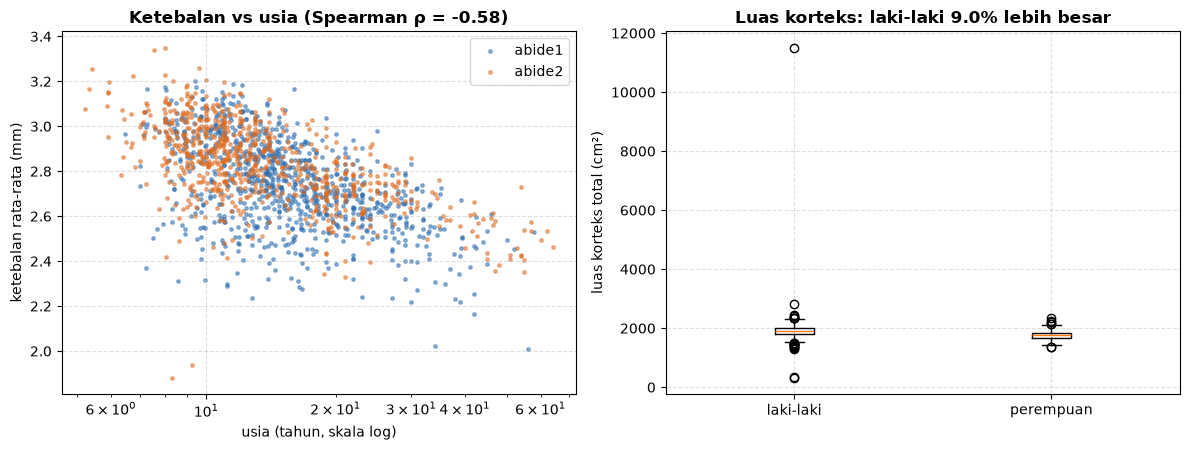

,ketebalan_rata,luas_total_cm2,volume_otak_cm3
dataset,,,
abide1,2.730000,1889.984009,1274.906006
abide2,2.840000,1885.875977,1257.719971


Ketebalan vs usia: ρ = -0.577 (p = 5.7e-146)


In [5]:
a0 = "hcp2016"
M = FITUR[f"morfo_{a0}"]
ringkas = pd.DataFrame({"usia": kohort["usia"], "jenis_kelamin": kohort["jenis_kelamin"], "label": kohort["label"], "dataset": kohort["dataset"],
                        "ketebalan_rata": (M[:, :, 2] * M[:, :, 0]).sum(1) / M[:, :, 0].sum(1),
                        "luas_total_cm2": M[:, :, 0].sum(1) / 100, "volume_otak_cm3": FITUR["volume_otak_mm3"] / 1000})
rho, p = stats.spearmanr(ringkas["usia"], ringkas["ketebalan_rata"])
lk, pr = ringkas[ringkas.jenis_kelamin == 1], ringkas[ringkas.jenis_kelamin == 2]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ds, w in [("abide1", "#2B6CB0"), ("abide2", "#DD6B20")]:
    d = ringkas[ringkas.dataset == ds]
    axes[0].scatter(d["usia"], d["ketebalan_rata"], s=6, alpha=0.5, color=w, label=ds)
axes[0].set_xscale("log"); axes[0].set_xlabel("usia (tahun, skala log)"); axes[0].set_ylabel("ketebalan rata-rata (mm)")
axes[0].set_title(f"Ketebalan vs usia (Spearman ρ = {rho:.2f})", fontweight="bold"); axes[0].legend()
axes[1].boxplot([lk["luas_total_cm2"], pr["luas_total_cm2"]]); axes[1].set_xticks([1, 2], ["laki-laki", "perempuan"])
axes[1].set_ylabel("luas korteks total (cm²)")
axes[1].set_title(f"Luas korteks: laki-laki {(lk['luas_total_cm2'].mean() / pr['luas_total_cm2'].mean() - 1) * 100:.1f}% lebih besar", fontweight="bold")
for ax in axes:
    ax.grid(alpha=0.4, ls="--")
plt.tight_layout()
fig.savefig(FIG_DIR / f"23_1_kewajaran_fitur_smri{akhiran}.png", dpi=150, bbox_inches="tight")
plt.show()

display(ringkas.groupby("dataset")[["ketebalan_rata", "luas_total_cm2", "volume_otak_cm3"]].median().round(3)
        .style.set_caption("Median fitur global per dataset"))
ringkas.to_csv(TABEL_DIR / f"23_ringkasan_fitur_smri{akhiran}.csv", index=False)
print(f"Ketebalan vs usia: ρ = {rho:.3f} (p = {p:.1e})")


### Kesimpulan

*(Diisi setelah melihat hasil.)*

**Langkah berikutnya:** notebook 13 (penjelasan setiap tahap pada satu subjek contoh dan verifikasi bahwa hasilnya identik dengan berkas ini), notebook 15 (ringkasan data terproses), lalu skenario S2–S4 yang memakai morfometri sebagai fitur simpul graf.